# Assignment 2 — Parkinson's Disease Classification
**Advanced Machine Learning 2026 — Team 20**

Follows the 7 tasks from the assignment brief. Fill in every `# TODO`. The test set is split
off in the very first cell and must not be touched again until Task 5 — every later cell that
needs data uses `X_trainval` / `y_trainval` only, never `X_test` / `y_test`, until the final
frozen-threshold evaluation.

Write figures/tables you want in the report to `Report/images/` and `Report/tables/`.


In [ ]:
# Setup: libraries, configuration, and dataset definitions:
# - Import libraries for data analysis, visualisation, and machine learning.
# - Use scikit-learn for preprocessing, cross-validation, SVM, and MLP models.
# - Define evaluation metrics, prioritising recall and F2-score.
# - Set RANDOM_STATE=42 to ensure reproducible results.
# - Specify the dataset path and Diagnosis as the binary prediction target.
# - Exclude PatientID and DoctorInCharge as non-predictive identifiers
#   to prevent spurious associations and potential data leakage.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (confusion_matrix, recall_score, precision_score,
                              fbeta_score, classification_report)

RANDOM_STATE = 42
DATA_PATH = "parkinsons_disease_data.csv"
TARGET = "Diagnosis"
DROP_COLS = ["PatientID", "DoctorInCharge"]  # explicitly excluded per the attribute description


In [ ]:
# Data loading and initial preparation:
# - Load the dataset from the specified CSV file.
# - Remove predefined columns that are irrelevant or unsuitable for prediction.
# - Check the dataset dimensions after removing these columns.
# - Display the first five rows to verify the structure and feature values.
# - Ensure DROP_COLS excludes identifiers or potential leakage variables,
#   without removing potentially useful predictors unnecessarily.

df = pd.read_csv(DATA_PATH)
df = df.drop(columns=DROP_COLS)
print(df.shape)
df.head()


(2105, 33)


,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,...,MoCA,FunctionalAssessment,Tremor,Rigidity,Bradykinesia,PosturalInstability,SpeechProblems,SleepDisorders,Constipation,Diagnosis
0,85,0,3,1,19.619878,0,5.108241,1.380660,3.893969,9.283194,...,29.181289,1.572427,1,0,0,0,0,0,0,0
1,75,0,0,2,16.247339,1,6.027648,8.409804,8.513428,5.602470,...,12.332639,4.787551,0,1,0,1,0,1,0,1
2,70,1,0,0,15.368239,0,2.242135,0.213275,6.498805,9.929824,...,29.927783,2.130686,1,0,0,0,1,0,1,1
3,52,0,0,0,15.454557,0,5.997788,1.375045,6.715033,4.196189,...,21.304268,3.391288,1,1,1,0,0,0,1,1
4,87,0,0,1,18.616042,0,9.775243,1.188607,4.657572,9.363925,...,8.336364,3.200969,0,0,0,1,0,1,0,0


## Reserve the test set now, before anything else

This has to happen before EDA-driven decisions, preprocessing fitting, or any tuning —
the brief is explicit that the test set may not influence model development in any way.
A stratified split keeps the PD/non-PD ratio the same in both halves.


In [ ]:
# Data splitting for model development and final evaluation:
# - Separate features (X) from the target variable Diagnosis (y).
# - Reserve 20% of the data as an independent hold-out test set.
# - Use the remaining 80% for training and cross-validation.
# - Stratification preserves the PD/Non-PD class proportions in both sets.
# - random_state ensures reproducibility of the split.
# - The test set remains untouched until final model evaluation in Task 5.
# - All preprocessing, feature selection, and hyperparameter tuning
#   must use training data only to prevent data leakage.

X = df.drop(columns=[TARGET])
y = df[TARGET]

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"Train/val: {len(X_trainval)} rows, {y_trainval.mean():.1%} PD")
print(f"Test:      {len(X_test)} rows, {y_test.mean():.1%} PD")


#NOTE: From here on: only X_trainval / y_trainval until Task 5's final evaluation.

Train/val: 1684 rows, 61.9% PD
Test:      421 rows, 62.0% PD


## 1. Problem Framing & EDA

### Target, intended use, and error costs
**TODO** — define the prediction target (PD vs. Non-PD) and describe a plausible intended
use (e.g. a screening/triage aid flagging patients for a clinical follow-up, not a diagnostic
replacement). Explain where the model sits in that workflow, and discuss what a false negative
(missed PD case) versus a false positive (unnecessary referral) costs in that context. State
explicitly which error type you weight more heavily, and why — this choice drives your metric
and threshold choices later, so don't leave it vague.

### Evaluation metrics
**TODO** — justify your chosen metrics given the error-cost discussion above. The brief later
fixes F2 as the threshold-selection criterion (Task 5), which already tells you recall is
weighted above precision project-wide — make sure your Task 1 metric discussion is consistent
with that, not contradicting it.


In [ ]:
# EDA: initial data quality and descriptive statistics:
# - Check for missing values across all features.
# - Identify duplicate rows that may affect model evaluation.
# - Summarise feature distributions, ranges, means, and standard deviations.
# - No missing values were found in the training/validation dataset.
# - Descriptive statistics help identify unusual values and potential data issues.
# - Any duplicate removal or data cleaning must be performed before modelling,
#   while preventing data leakage between training and test sets.

print(df.isna().sum()[df.isna().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().T

Series([], dtype: int64)

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Age,2105.0,69.601900,11.594511,50.000000,60.000000,70.000000,80.000000,89.000000
Gender,2105.0,0.492637,0.500065,0.000000,0.000000,0.000000,1.000000,1.000000
Ethnicity,2105.0,0.692637,1.003827,0.000000,0.000000,0.000000,1.000000,3.000000
EducationLevel,2105.0,1.337292,0.895840,0.000000,1.000000,1.000000,2.000000,3.000000
BMI,2105.0,27.209493,7.208099,15.008333,20.782176,27.184571,33.462452,39.999887
Smoking,2105.0,0.296437,0.456795,0.000000,0.000000,0.000000,1.000000,1.000000
AlcoholConsumption,2105.0,10.040413,5.687014,0.002228,5.150278,10.070337,14.829565,19.988866
PhysicalActivity,2105.0,5.016674,2.890919,0.004157,2.455703,5.031550,7.512795,9.995255
DietQuality,2105.0,4.912901,2.872115,0.000011,2.478503,4.825187,7.381487,9.995864
SleepQuality,2105.0,6.996639,1.753065,4.000497,5.488864,6.929819,8.558719,9.999821


Diagnosis
PD        0.619359
Non-PD    0.380641
Name: proportion, dtype: float64


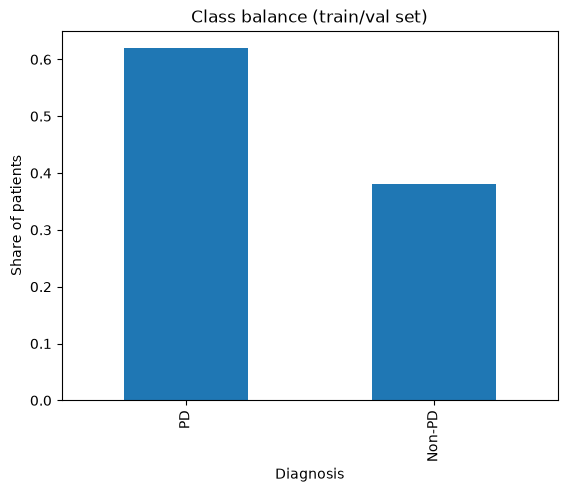

In [ ]:
# EDA: class balance in the training/validation dataset:
# - PD represents 61.9% of observations, compared to 38.1% Non-PD.
# - This indicates moderate class imbalance, with PD as the majority class.
# - Stratified cross-validation will preserve class proportions across folds.
# - Recall and F2-score are prioritised over accuracy alone to minimise
#   missed PD cases (false negatives).
# - Resampling is not applied automatically; its need depends on model performance.

class_balance = y_trainval.value_counts(normalize=True).rename({0: "Non-PD", 1: "PD"})
print(class_balance)
class_balance.plot(kind="bar", title="Class balance (train/val set)")
plt.ylabel("Share of patients")
plt.savefig("Report/images/class_balance.png", dpi=150, bbox_inches="tight")  # TODO: create Report/images/ first
plt.show()


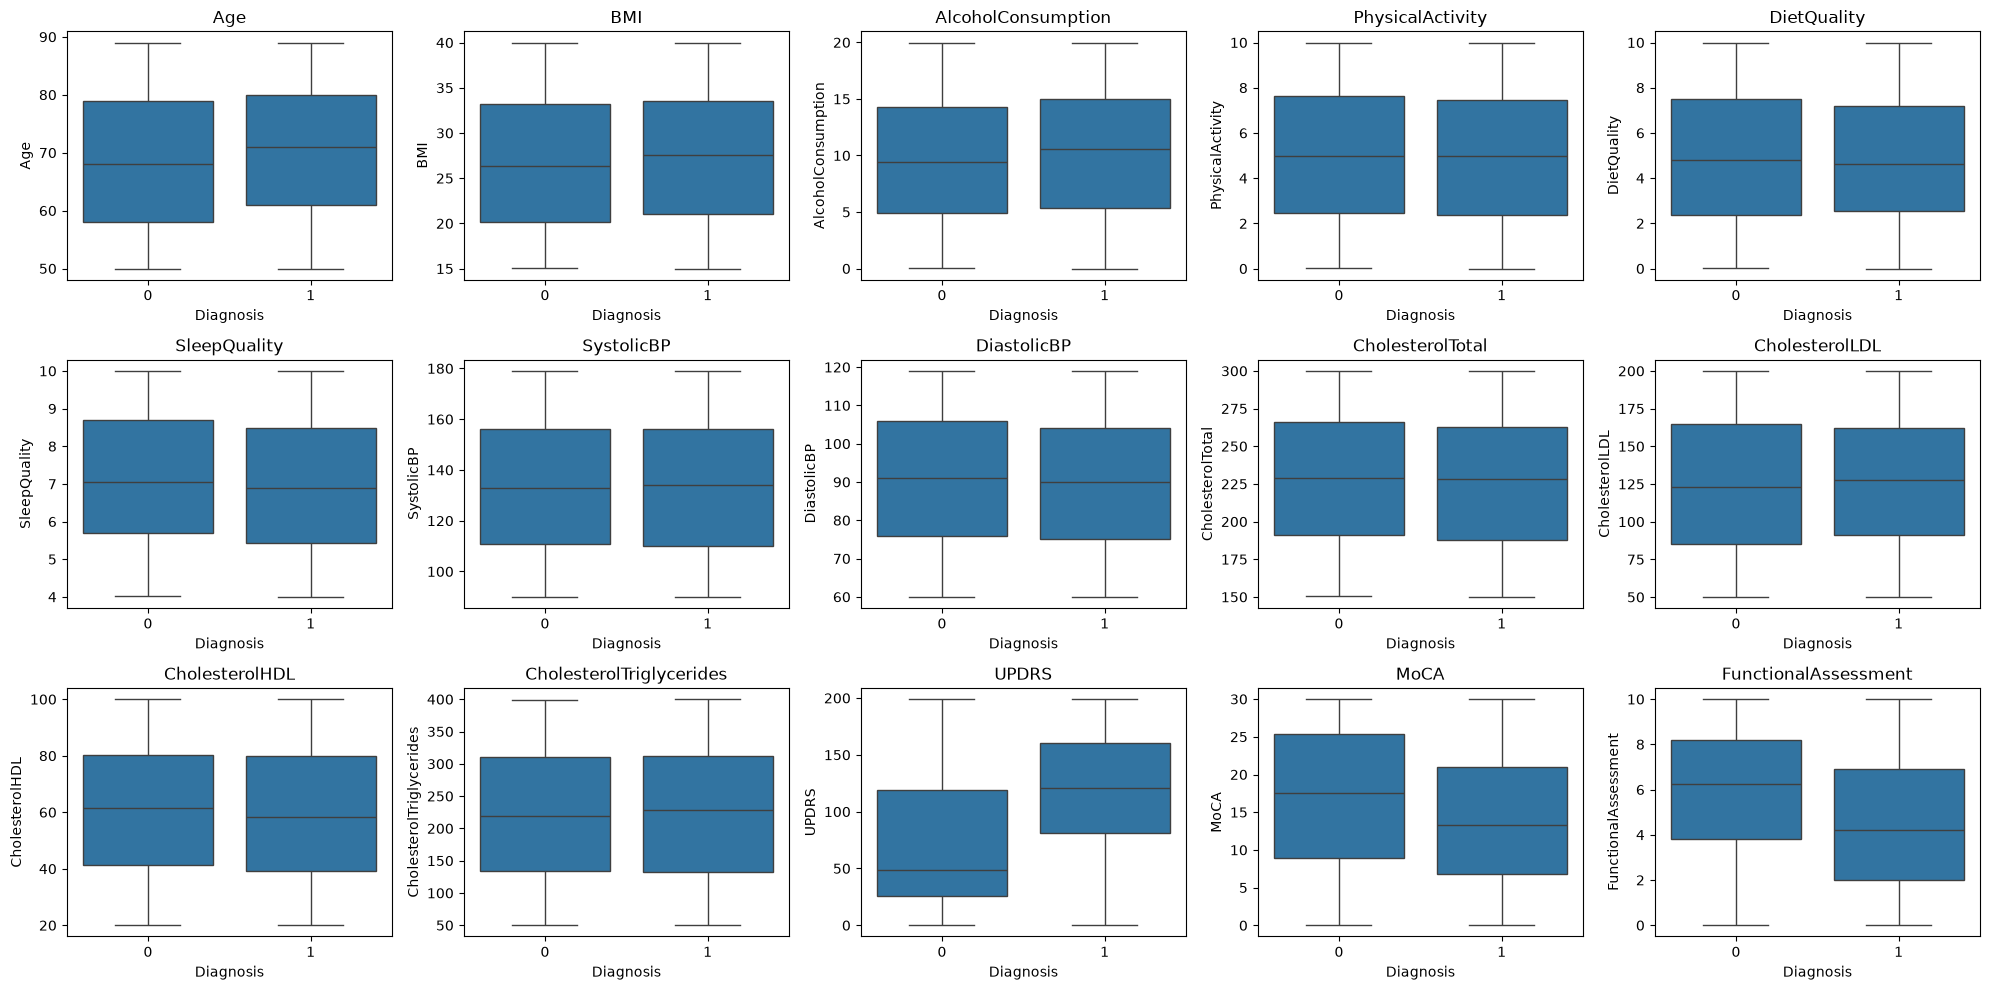

In [ ]:
# EDA: outlier detection and class distribution of continuous features:
# - Boxplots compare feature distributions between PD and Non-PD.
# - Potential outliers are identified using the 1.5 × IQR criterion.
# - No visible statistical outliers were observed in either class.
# - UPDRS, FunctionalAssessment, and MoCA show the clearest class differences.
# - Other continuous features show substantial overlap between classes.
# - No outlier removal is required based on these findings.
# - Boxplots do not verify clinically valid feature ranges.

# Outlier check on the continuous clinical variables.
continuous_cols = ["Age", "BMI", "AlcoholConsumption", "PhysicalActivity", "DietQuality",
                    "SleepQuality", "SystolicBP", "DiastolicBP", "CholesterolTotal",
                    "CholesterolLDL", "CholesterolHDL", "CholesterolTriglycerides",
                    "UPDRS", "MoCA", "FunctionalAssessment"]

fig, axes = plt.subplots(3, 5, figsize=(20, 10))

for ax, col in zip(axes.flat, continuous_cols):
    sns.boxplot(
        x=y_trainval,
        y=X_trainval[col],
        ax=ax,
        showfliers=True,
        flierprops={
            "marker": "o",
            "markersize": 5,
            "markerfacecolor": "red",
            "markeredgecolor": "black",
            "alpha": 0.8
        }
    )
    ax.set_title(col)

plt.tight_layout()
plt.savefig(
    "Report/images/continuous_feature_boxplots.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

#### **Boxplot Analysis**
Boxplots were used to examine the distributions of continuous clinical variables across the PD and Non-PD groups. No statistical outliers were observed using the standard 1.5 × IQR criterion.

Most demographic, lifestyle, and cardiovascular variables showed substantial overlap between the two groups. In contrast, UPDRS, MoCA, and FunctionalAssessment showed noticeable differences in their distributions, suggesting that these variables may have predictive value for distinguishing PD from Non-PD patients.

No observations were removed based on the boxplot analysis.

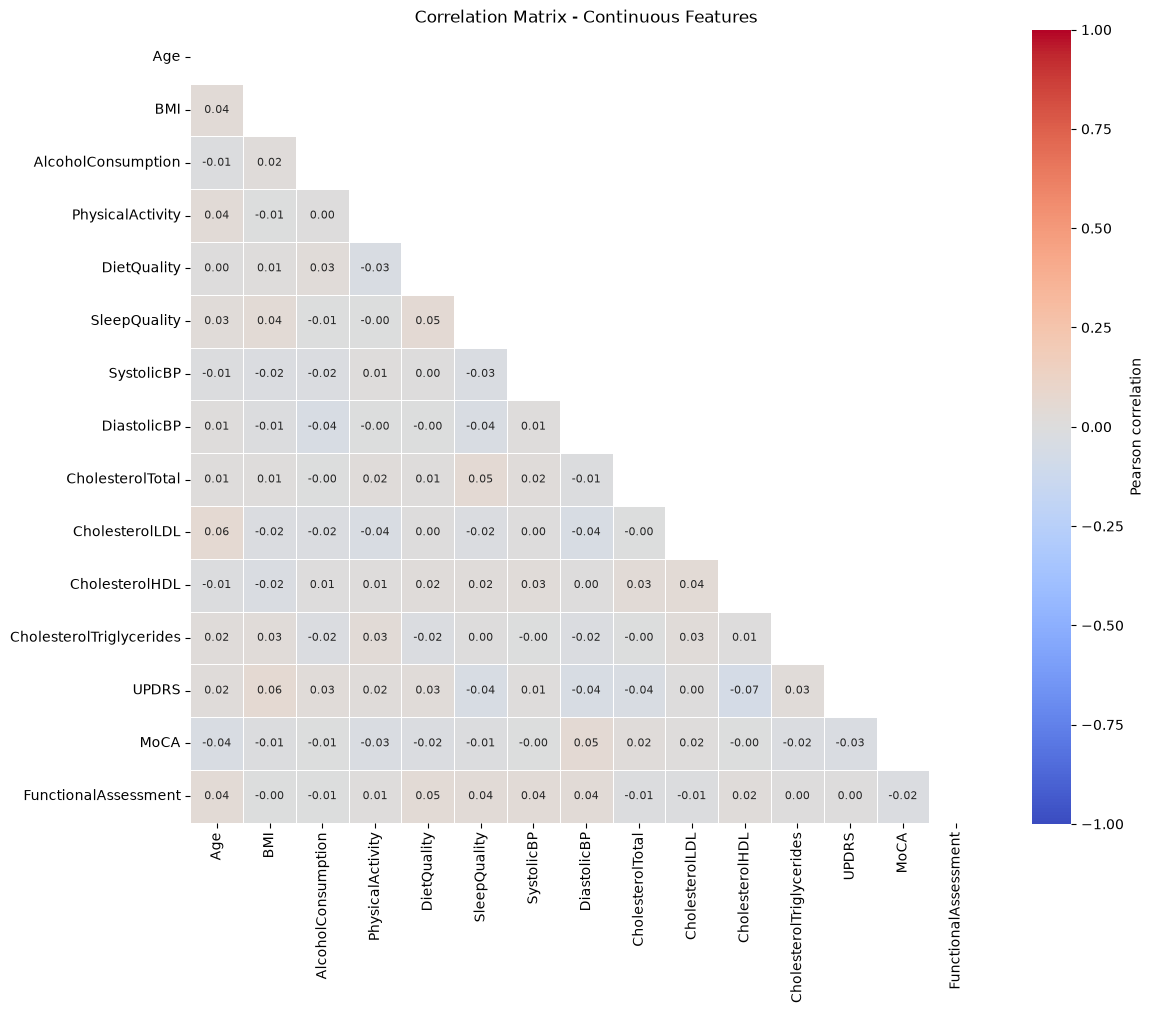

In [ ]:
# EDA: Pearson correlation matrix of continuous features:
# - Examines linear relationships and potential multicollinearity.
# - Only the lower triangle is shown to avoid duplicate information.
# - Correlations are very weak (approximately -0.07 to +0.06).
# - No strongly correlated feature pairs were identified.
# - No feature removal is needed based on pairwise correlations.
# - Weak linear correlations do not exclude non-linear relationships.

corr = X_trainval[continuous_cols].corr()

# Hide upper triangle, including diagonal
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(12, 10))

sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Pearson correlation"}
)

plt.title("Correlation Matrix - Continuous Features")
plt.tight_layout()
plt.savefig(
    "Report/images/correlation_matrix.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

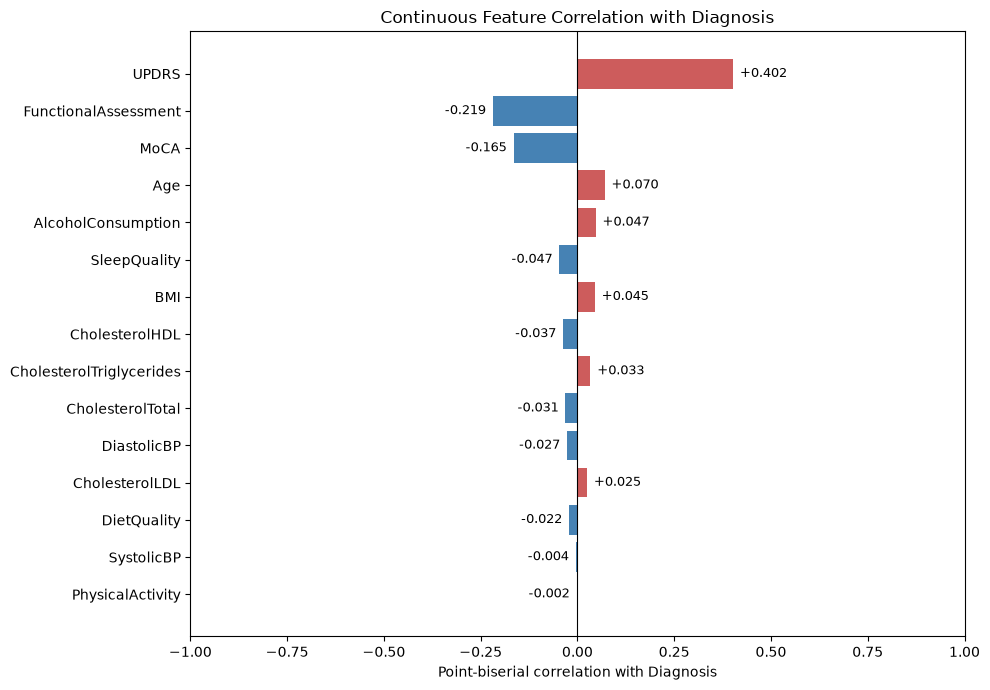

UPDRS                       0.402
FunctionalAssessment       -0.219
MoCA                       -0.165
Age                         0.070
AlcoholConsumption          0.047
SleepQuality               -0.047
BMI                         0.045
CholesterolHDL             -0.037
CholesterolTriglycerides    0.033
CholesterolTotal           -0.031
DiastolicBP                -0.027
CholesterolLDL              0.025
DietQuality                -0.022
SystolicBP                 -0.004
PhysicalActivity           -0.002
dtype: float64


In [ ]:
# EDA: correlation between continuous features and Diagnosis:
# - Point-biserial correlation measures association with the binary target.
# - Features are ranked by absolute correlation strength.
# - UPDRS (r=0.402) shows the strongest positive association with PD.
# - FunctionalAssessment (r=-0.219) and MoCA (r=-0.165) show negative associations.
# - Other continuous features have very weak correlations with Diagnosis.
# - These findings support selecting UPDRS, FunctionalAssessment, and MoCA
#   as potential FIS inputs, subject to clinical relevance and availability.
# - Weak correlations do not exclude non-linear predictive relationships.

# Correlation between continuous features and Diagnosis
target_corr = X_trainval[continuous_cols].corrwith(y_trainval)

# Sort by absolute correlation (strongest first)
target_corr = target_corr.reindex(
    target_corr.abs().sort_values(ascending=False).index
)

fig, ax = plt.subplots(figsize=(10, 7))

# Colors based on correlation direction
colors = [
    "indianred" if v > 0 else "steelblue"
    for v in target_corr.values
]

bars = ax.barh(
    target_corr.index,
    target_corr.values,
    color=colors
)

# Strongest correlations at the top
ax.invert_yaxis()

# Add correlation values to each bar
for bar, value in zip(bars, target_corr.values):
    ax.annotate(
        f"{value:+.3f}",
        xy=(value, bar.get_y() + bar.get_height() / 2),
        xytext=(5 if value >= 0 else -5, 0),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=9
    )

# Formatting
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-1, 1)
ax.set_xlabel("Point-biserial correlation with Diagnosis")
ax.set_ylabel("")
ax.set_title("Continuous Feature Correlation with Diagnosis")

plt.tight_layout()
plt.savefig(
    "Report/images/target_correlations.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# Print exact correlations
print(target_corr.round(3))

### **Correlation Analysis**
The point-biserial correlation analysis shows that UPDRS has the strongest association with Diagnosis (r = 0.402), followed by FunctionalAssessment (r = -0.219) and MoCA (r = -0.165). Higher UPDRS scores are associated with Parkinson's Disease, while lower functional and cognitive assessment scores are associated with PD.

All remaining continuous features show very weak correlations with Diagnosis (|r| ≤ 0.070). These results suggest that UPDRS, FunctionalAssessment, and MoCA are the most informative individual continuous features in terms of linear association with the target.

In [ ]:
# EDA checks for class balance and missing values:
# - Class distribution: assess imbalance between PD and Non-PD.
# - Class percentages: 61.9% PD and 38.1% Non-PD, indicating moderate imbalance.
# - Missing values: check data completeness before preprocessing.
# - No missing values found; imputation is therefore unnecessary.
# - Class imbalance supports using stratified cross-validation and
#   prioritising recall and F2-score over accuracy alone.

# Class balance
print("Class distribution:")
print(y_trainval.value_counts())
print("\nClass percentages:")
print((y_trainval.value_counts(normalize=True) * 100).round(1))

# Missing values
print("\nMissing values per feature:")
print(X_trainval.isnull().sum())

print("\nTotal missing values:")
print(X_trainval.isnull().sum().sum())

Class distribution:
Diagnosis
1    1043
0     641
Name: count, dtype: int64

Class percentages:
Diagnosis
1    61.9
0    38.1
Name: proportion, dtype: float64

Missing values per feature:
Age                         0
Gender                      0
Ethnicity                   0
EducationLevel              0
BMI                         0
Smoking                     0
AlcoholConsumption          0
PhysicalActivity            0
DietQuality                 0
SleepQuality                0
FamilyHistoryParkinsons     0
TraumaticBrainInjury        0
Hypertension                0
Diabetes                    0
Depression                  0
Stroke                      0
SystolicBP                  0
DiastolicBP                 0
CholesterolTotal            0
CholesterolLDL              0
CholesterolHDL              0
CholesterolTriglycerides    0
UPDRS                       0
MoCA                        0
FunctionalAssessment        0
Tremor                      0
Rigidity                    0
Br

### **EDA Findings and Implications**

The training/validation dataset contains 1,684 observations, with 61.9% diagnosed with Parkinson's Disease (PD) and 38.1% classified as Non-PD. This indicates a moderate class imbalance. No missing values were found, and the boxplots revealed no statistical outliers using the 1.5 × IQR criterion.

The correlation analysis identified UPDRS as the feature most strongly associated with Diagnosis (r = 0.402), followed by FunctionalAssessment (r = -0.219) and MoCA (r = -0.165). The boxplots confirmed visible differences between the PD and Non-PD groups for these variables. Other continuous features showed weak correlations with Diagnosis. Pairwise correlations between continuous features were also very low, suggesting no strong linear multicollinearity.

*Implications for Task 2 (Preprocessing):* No missing-value imputation or outlier removal is currently required. Feature scaling should be considered for scale-sensitive models. Given the moderate class imbalance, evaluation should prioritise recall and F2-score rather than accuracy alone. Any resampling, if used, should be applied only to the training data.

*Implications for Task 3 (FIS):* UPDRS, FunctionalAssessment, and MoCA are promising candidates for FIS inputs because of their associations with Diagnosis and their clinical interpretability. The final selection should consider the availability of these measurements at prediction time and the complexity of the fuzzy rule base.

## 2. Preprocessing & Feature Engineering

Binary/ordinal columns (Gender, Smoking, the yes/no symptom flags, etc.) need no scaling.
Continuous columns get standardized. Ethnicity and EducationLevel are categorical with more
than two levels, so they get one-hot encoded rather than treated as ordinal integers — treating
them as plain numbers would imply a false ordering.

In [ ]:
# Feature groups and preprocessing choices based on EDA:
# - Continuous: standardised for scale-sensitive SVM and MLP models.
# - Categorical: one-hot encoded to avoid artificial numerical ordering.
# - Binary: retained as 0/1 without transformation.
# - All 32 original features retained: no strong pairwise correlations
#   or visible IQR outliers; near-zero variance still needs verification.
# - No imputation required, as no missing values were found.
# - Preprocessing will be fitted within each cross-validation training fold
#   to prevent data leakage.

# Feature groups
categorical_cols = ["Ethnicity", "EducationLevel"]

binary_cols = [
    "Gender", "Smoking", "FamilyHistoryParkinsons",
    "TraumaticBrainInjury", "Hypertension", "Diabetes",
    "Depression", "Stroke", "Tremor", "Rigidity",
    "Bradykinesia", "PosturalInstability", "SpeechProblems",
    "SleepDisorders", "Constipation"
]

# continuous_cols defined in Task 1
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), continuous_cols),
        ("cat", OneHotEncoder(
            handle_unknown="ignore"
        ), categorical_cols),
        ("bin", "passthrough", binary_cols)
    ]
)

In [ ]:
# Model pipelines for SVM and MLP:
# - Both models use the same preprocessing for a fair comparison.
# - SVM: suitable for complex, potentially non-linear decision boundaries.
# - MLP: captures non-linear relationships and feature interactions.
# - max_iter=1000 allows sufficient iterations for MLP convergence.
# - random_state=42 ensures reproducible MLP initialisation.
# - Pipelines prevent data leakage by fitting preprocessing separately
#   within each cross-validation training fold.
# - Model hyperparameters will be optimised during cross-validation.

svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC())
])

mlp_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        max_iter=1000,
        random_state=42
    ))
])

In [ ]:
# Feature retention decision:
# - No constant features were identified among the 32 predictors.
# - Stroke has the lowest variation (95% identical values).
# - Rare binary features may still provide clinically relevant information.
# - No strong pairwise correlations were found among continuous features.
# - All 32 original features are retained for SVM and MLP.
# - No additional feature engineering is applied at this stage.

feature_variation = pd.DataFrame({
    "Unique values": X_trainval.nunique(),
    "Most frequent value (%)": (
        X_trainval.apply(
            lambda col: col.value_counts(normalize=True).iloc[0]
        ) * 100
    ).round(1)
})

print(
    feature_variation.sort_values(
        "Most frequent value (%)",
        ascending=False
    )
)

                          Unique values  Most frequent value (%)
Stroke                                2                     95.0
TraumaticBrainInjury                  2                     89.5
PosturalInstability                   2                     86.2
FamilyHistoryParkinsons               2                     85.3
Diabetes                              2                     85.3
Hypertension                          2                     85.2
Depression                            2                     80.0
Bradykinesia                          2                     78.9
SleepDisorders                        2                     75.5
Rigidity                              2                     74.6
SpeechProblems                        2                     70.8
Smoking                               2                     70.2
Constipation                          2                     69.7
Ethnicity                             4                     60.5
Tremor                   

### **Preprocessing and Feature Engineering**

Based on the EDA findings, all 32 predictive features were retained. No missing values, constant features, or visible statistical outliers were identified. Although Stroke showed limited variation (95% identical values), it was retained because rare clinical conditions may still provide predictive information. No strong pairwise correlations were found among continuous features, and no additional feature engineering was considered necessary.

A ColumnTransformer was defined to apply feature-specific preprocessing:
- Continuous features (15): StandardScaler to standardise numerical values for scale-sensitive SVM and MLP models.
- Categorical features (2): OneHotEncoder to represent categories without imposing artificial numerical relationships.
- Binary features (15): Retained in their original 0/1 representation.

To prevent data leakage, preprocessing is integrated into the SVM and MLP pipelines, ensuring that transformations are fitted exclusively on the training portion of each cross-validation fold. The held-out test set remains untouched until final evaluation.

For the Fuzzy Inference System (FIS), UPDRS, FunctionalAssessment, and MoCA were identified as potential inputs based on their associations with Diagnosis and clinical interpretability. Their original measurement scales will be preserved, and any data-dependent membership function parameters will be determined using training data only.

Overall, the preprocessing strategy maintains the available predictive information while supporting a consistent, reproducible, and leakage-free comparison of the models.

## 3. Models

**FIS preprocessing:** Unlike SVM and MLP, the FIS uses its own preprocessing based on the selected clinical features. Any data-dependent
membership function parameters are determined using training data only and applied unchanged to validation and test data to prevent data leakage.

### SVM — linear and RBF kernels
Both kernels are candidate configurations within the same SVM family; Task 4 picks the best
one across both for the final model comparison.


In [27]:
svm_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("clf", SVC(probability=True, random_state=RANDOM_STATE)),
])

# Quick baseline fit, just to confirm the pipeline runs end to end — real tuning is Task 4.
svm_pipeline.set_params(clf__kernel="rbf")
svm_pipeline.fit(X_trainval, y_trainval)
print("Baseline RBF-SVM train accuracy:", svm_pipeline.score(X_trainval, y_trainval))


c:\Projects\Advanced Machine Learning\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Baseline RBF-SVM train accuracy: 0.9376484560570071


### MLP

In [28]:
mlp_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("clf", MLPClassifier(random_state=RANDOM_STATE, max_iter=1000)),
])

mlp_pipeline.fit(X_trainval, y_trainval)
print("Baseline MLP train accuracy:", mlp_pipeline.score(X_trainval, y_trainval))


Baseline MLP train accuracy: 1.0


### Fuzzy Inference System (FIS)

Inputs chosen (4-6 continuous variables, relevance motivated by the attribute description):

- **UPDRS** — the Unified Parkinson's Disease Rating Scale score is the standard clinical
  severity measure for PD, higher = more severe motor symptoms.
- **MoCA** — cognitive assessment; PD is commonly associated with cognitive decline, lower
  score = more impairment.
- **FunctionalAssessment** — a general functional-impairment score, lower = more impaired,
  directly relevant since PD affects daily functioning.
- **Age** — PD risk and prevalence rise with age, a well-established epidemiological factor.
- **SleepQuality** — sleep disorders are a recognized non-motor symptom associated with PD.

**TODO — back this list with a citation** (the course expects the assignment's data
description and/or literature, not just intuition) and adjust the set if your EDA in Task 1
suggests a different variable separates the classes better.


In [ ]:
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# Define the fuzzy ranges from the TRAINING data only (per the brief's leakage warning for FIS).
fis_inputs_cols = ["UPDRS", "MoCA", "FunctionalAssessment", "Age", "SleepQuality"]
ranges = {col: (X_trainval[col].min(), X_trainval[col].max()) for col in fis_inputs_cols}
print(ranges)

# TODO: build the skfuzzy Antecedent for each input with 2-3 membership functions
# (e.g. low/medium/high, or low/high), using `ranges` above — not X_test's min/max.
# updrs = ctrl.Antecedent(np.arange(ranges["UPDRS"][0], ranges["UPDRS"][1], 1), "UPDRS")
# updrs["low"]    = fuzz.trimf(updrs.universe, [...])
# updrs["medium"] = fuzz.trimf(updrs.universe, [...])
# updrs["high"]   = fuzz.trimf(updrs.universe, [...])
# ... repeat for the other 4 inputs ...

# risk = ctrl.Consequent(np.arange(0, 1.01, 0.01), "pd_risk")
# risk["low"] = fuzz.trimf(risk.universe, [0, 0, 0.5])
# risk["high"] = fuzz.trimf(risk.universe, [0.5, 1, 1])

# TODO: write 4-8 rules connecting input membership combinations to a risk level, e.g.
# rule1 = ctrl.Rule(updrs["high"] & moca["low"], risk["high"])
# ...

# fis_ctrl = ctrl.ControlSystem([rule1, rule2, ...])
# fis = ctrl.ControlSystemSimulation(fis_ctrl)

# TODO: wrap this in a function that takes a row of X and returns a risk score in [0,1]
# via centroid defuzzification (skfuzzy does this automatically when you call fis.compute()).


**TODO — document source-to-model traceability.** For each input, state in one sentence
where the relevance claim comes from (attribute description and/or a cited paper), and for
each rule, state the clinical/common-sense reasoning connecting the input combination to the
risk level. This traceability is explicitly what's being graded here, not clinical accuracy.


## 4. Validation & Hyperparameter Optimization

Stratified cross-validation on `X_trainval` / `y_trainval` only. The SVM family (linear + RBF
combined) gets at most 20 configurations total, MLP gets at most 20 — plan the grids with that
cap in mind rather than running something broad and trimming after the fact.


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# SVM family: linear + rbf combined must not exceed 20 fits. Example: 2 kernels x up to 10
# C/gamma combinations. Adjust so the grid total stays under the cap -- GridSearchCV will
# tell you the total via len(grid.cv_results_['params']).
svm_param_grid = [
    {"clf__kernel": ["linear"], "clf__C": [0.01, 0.1, 1, 10, 100]},
    {"clf__kernel": ["rbf"], "clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.1, 1, 10]},
]

svm_grid = GridSearchCV(svm_pipeline, param_grid=svm_param_grid, scoring="recall",
                         cv=cv, n_jobs=-1)
svm_grid.fit(X_trainval, y_trainval)
print("Total SVM configurations evaluated:", len(svm_grid.cv_results_["params"]))
print("Best SVM params:", svm_grid.best_params_)
print("Best SVM CV score (search score, not your final reported number):", svm_grid.best_score_)


In [ ]:
mlp_param_grid = {
    "clf__hidden_layer_sizes": [(32,), (64,), (32, 16), (64, 32)],
    "clf__alpha": [0.0001, 0.001, 0.01],
    "clf__learning_rate_init": [0.001, 0.01],
}
# TODO: count the combinations above (4 x 3 x 2 = 24) and trim to <=20, e.g. drop one
# hidden_layer_sizes option, before running this for real.

mlp_grid = GridSearchCV(mlp_pipeline, param_grid=mlp_param_grid, scoring="recall",
                         cv=cv, n_jobs=-1)
mlp_grid.fit(X_trainval, y_trainval)
print("Total MLP configurations evaluated:", len(mlp_grid.cv_results_["params"]))
print("Best MLP params:", mlp_grid.best_params_)
print("Best MLP CV score (search score, not your final reported number):", mlp_grid.best_score_)


**TODO — motivate your validation strategy and search choices** in the report: why 5-fold,
why `scoring="recall"` as the search objective versus something else given your Task 1 cost
discussion, and why this particular grid rather than a wider/narrower one.

**FIS validation**: there's no hyperparameter search in the same sense, but the brief still
wants an explicit validation procedure. **TODO** — describe how you refined membership
functions/rules using only `X_trainval` (e.g. inspect the risk-score distribution per class on
a validation split, adjust membership boundaries if the two classes don't separate), and
confirm you did not touch the test set while doing this.


## 5. Model Selection & Thresholding

Split a validation set out of `X_trainval` (not touching `X_test`), refit the best
configuration of each model on the remaining training data, score the validation set, then
pick each model's threshold by maximizing F2 on those validation scores. Every model uses the
same rule — only the resulting number differs.


In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.2, stratify=y_trainval, random_state=RANDOM_STATE)

best_svm = svm_grid.best_estimator_
best_svm.fit(X_train, y_train)
svm_val_scores = best_svm.predict_proba(X_val)[:, 1]

best_mlp = mlp_grid.best_estimator_
best_mlp.fit(X_train, y_train)
mlp_val_scores = best_mlp.predict_proba(X_val)[:, 1]

# TODO: retrain/recompute the FIS on X_train only (or however your FIS validation
# procedure from Task 4 works), then produce fis_val_scores for X_val the same way.


In [ ]:
def best_f2_threshold(y_true, scores):
    thresholds = np.linspace(0.01, 0.99, 99)
    f2_scores = [fbeta_score(y_true, scores >= t, beta=2, zero_division=0) for t in thresholds]
    best_idx = int(np.argmax(f2_scores))
    return thresholds[best_idx], f2_scores[best_idx]

svm_threshold, svm_val_f2 = best_f2_threshold(y_val, svm_val_scores)
mlp_threshold, mlp_val_f2 = best_f2_threshold(y_val, mlp_val_scores)
# fis_threshold, fis_val_f2 = best_f2_threshold(y_val, fis_val_scores)

print(f"SVM threshold: {svm_threshold:.2f} (val F2 = {svm_val_f2:.3f})")
print(f"MLP threshold: {mlp_threshold:.2f} (val F2 = {mlp_val_f2:.3f})")
# Freeze these numbers here. Do not recompute them after looking at the test set below.


In [ ]:
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp)

def evaluate_on_test(name, model, threshold, X_test=X_test, y_test=y_test):
    scores = model.predict_proba(X_test)[:, 1]
    preds = (scores >= threshold).astype(int)
    print(f"--- {name} (threshold={threshold:.2f}) ---")
    print("Confusion matrix:\n", confusion_matrix(y_test, preds))
    print(f"Recall:      {recall_score(y_test, preds):.3f}")
    print(f"Precision:   {precision_score(y_test, preds):.3f}")
    print(f"Specificity: {specificity_score(y_test, preds):.3f}")
    print(f"F2:          {fbeta_score(y_test, preds, beta=2):.3f}")
    print()

# Refit the chosen configurations on the FULL train/val set before the final test evaluation --
# the validation split above was only for threshold calibration, not for the final fit.
best_svm.fit(X_trainval, y_trainval)
best_mlp.fit(X_trainval, y_trainval)

evaluate_on_test("SVM", best_svm, svm_threshold)
evaluate_on_test("MLP", best_mlp, mlp_threshold)
# evaluate_on_test("FIS", fis_wrapper, fis_threshold)  # TODO once the FIS scoring function exists


**TODO — present the three models' frozen-threshold test results side by side** in a table
for the report, and make sure the text explicitly calls out that these thresholds were set on
validation data and never adjusted after seeing these test numbers.


## 6. Decision Support & Practical Value

**TODO** — mostly narrative, written against the Task 1 workflow definition and the Task 5
results table:
- Which model would you recommend, and why, with numbers from Task 5 backing it up.
- Who uses the model's output and what decision/action it supports (e.g. a clinician deciding
  whether to refer a patient for further specialist assessment).
- A simple decision policy connecting score to action (e.g. "flag for review if risk score
  exceeds the frozen threshold", possibly with an intermediate "borderline" band).
- Cost implications of false positives/negatives in this specific workflow, tying back to
  Task 1's discussion.
- What assumptions underlie the claim that this creates value (e.g. assumes clinician
  capacity exists to review flagged cases, assumes the synthetic data's feature relationships
  hold on real patients, which they may not).


In [ ]:
# Optional supporting numbers for Task 6: how many of the test patients would be flagged
# under the recommended model's frozen threshold, split by true label.
# TODO: fill in once you've picked the recommended model from the table above.
# recommended_scores = best_svm.predict_proba(X_test)[:, 1]  # or whichever model
# recommended_preds = (recommended_scores >= svm_threshold).astype(int)
# pd.crosstab(y_test, recommended_preds, rownames=["Actual"], colnames=["Flagged"])


## 7. Reflection

**TODO** — nobody on the team is currently assigned this section, worth flagging in standup.
Cover: what worked best and why (bias-variance, linearity vs. SVM kernel choice, MLP capacity
and regularization via `alpha`, amount of training data relative to feature count), challenges
encountered and how you addressed them (e.g. anything that came up tuning the FIS), and the
main limitations plus concrete future improvements.
